In [37]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from sklearn.linear_model import LinearRegression
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression

# Goal: Find logMdot = A + blogL + dlogP
# Goal: Find logMdot = A + blogL + clogM
# Goal: Find logMdot = A + blogL + clogM + dlogP

In [27]:
DataToFit = np.transpose(np.asarray(np.genfromtxt('MstarsForHenry.csv',delimiter=',',skip_header=1)))

In [28]:
def PulsationModeSort (input_array):
    FundamentalPulsators = []
    OvertonePulsators = []
    i = 0
    while i < len(input_array[18]):
        if input_array[18][i] == 0 and input_array[6][i] <= 0.4:
            FundamentalPulsators.append(i)
        if input_array[18][i] == 1 and input_array[6][i] <= 0.4:
            OvertonePulsators.append(i)
        i += 1
    FundamentalModeStars = np.transpose(input_array.transpose()[FundamentalPulsators])
    FirstOvertoneModeStars = np.transpose(input_array.transpose()[OvertonePulsators])
    return FundamentalModeStars, FirstOvertoneModeStars

def MassSort (input_array):
    logMLT005 = []
    logMGT005 = []
    i = 0
    while i < len(input_array[18]):
        if input_array[6][i] <= 0.05: # For all stars with logM < 0.05
            logMLT005.append(i)
        if input_array[6][i] > -0.05 and input_array[6][i] <= 0.4 : # For all stars with logM > -0.05 - yes, there needs to be overlap!
            logMGT005.append(i)
        if input_array[6][i] > 0.4:
            print("Star", i, "of mass",10**(input_array[6][i]),"cut")
        i += 1
    #LowMassStars = np.transpose(input_array.transpose()[logMLT005])
    #HighMassStars = np.transpose(input_array.transpose()[logMGT005])
    return logMLT005, logMGT005

def MassFilter (Mass_Data):
    logMListArray = []
    i = 0
    while i<len(Mass_Data):
        if Mass_Data[i] < 0.4:
            logMListArray.append(i)
        i += 1
    return logMListArray

FundamentalDataToFit, FirstOvertoneDataToFit = PulsationModeSort(DataToFit)
LowLogMToFitStars, HighLogMToFitStars = MassSort(DataToFit)

Star 0 of mass 2.897010037894646 cut
Star 2 of mass 3.8369841040816137 cut
Star 3 of mass 3.5729751853768725 cut
Star 4 of mass 3.324987370229426 cut
Star 5 of mass 2.641982885673074 cut
Star 6 of mass 2.686024687552101 cut
Star 7 of mass 3.1340072730838595 cut
Star 8 of mass 3.597990397965188 cut
Star 10 of mass 2.768024947580895 cut
Star 12 of mass 3.3569896324664192 cut
Star 13 of mass 2.932986067730905 cut
Star 14 of mass 3.6170124197260307 cut
Star 16 of mass 3.185004131304742 cut
Star 17 of mass 3.2870022396877525 cut
Star 18 of mass 2.5220285581992528 cut
Star 19 of mass 2.8680056330868973 cut
Star 21 of mass 2.7459966305247128 cut
Star 22 of mass 3.460987254853527 cut
Star 23 of mass 3.383997238792015 cut
Star 24 of mass 3.6310313617986782 cut
Star 26 of mass 3.401966243904304 cut
Star 28 of mass 3.640994308017578 cut
Star 29 of mass 2.9459813964963733 cut
Star 30 of mass 2.5340197766877206 cut
Star 31 of mass 3.2250020868740727 cut
Star 32 of mass 2.5980051043232657 cut
Star 3

In [29]:
# All Stars
logMData = DataToFit[6]
logMLT005Data = DataToFit[6][LowLogMToFitStars]
logMMGT005Data = DataToFit[6][HighLogMToFitStars]
logRData = DataToFit[9]
logRMLT005Data = DataToFit[9][LowLogMToFitStars]
logRMGT005Data = DataToFit[9][HighLogMToFitStars]
logLData = DataToFit[7]
logLLT005Data = DataToFit[7][LowLogMToFitStars]
logLMGT005Data = DataToFit[7][HighLogMToFitStars]

# Fundamental Mode
FundlogMData = FundamentalDataToFit[6]
FundlogRData = FundamentalDataToFit[9]
FundlogLData = FundamentalDataToFit[7]
logP0Data = FundamentalDataToFit[15]

# First Overtone
FirstOverlogMData = FirstOvertoneDataToFit[6]
FirstOverlogRData = FirstOvertoneDataToFit[9]
FirstOverlogLData = FirstOvertoneDataToFit[7]
logP1Data = FirstOvertoneDataToFit[17]

In [30]:
inArray = np.transpose(np.vstack((logLData,logMData))) # First, let's find logR = A + B logL + C logM for ALL STARS
x = inArray
y = logRData
# x, y = np.array(x), np.array(y)
model = LinearRegression().fit(x, y)
# Returns a linear regression y = b0 + sum(b_i*x_i,i=1 to n)
r_sq = model.score(x, y)
print('coefficient of determination:', r_sq)
print('intercept:', model.intercept_) # b0
print('slope:', model.coef_) # b1, b2, b3,..., bn

coefficient of determination: 0.9952199639190396
intercept: -0.18574878232514402
slope: [ 0.6713771 -0.2173414]


In [31]:
inArray = np.transpose(np.vstack((logLLT005Data,logMLT005Data, logMLT005Data**2))) # Next, let's find logR = A + B logL + C logM + D logM**2 for log M < 0.05
x = inArray
y = logRMLT005Data
# x, y = np.array(x), np.array(y)
model = LinearRegression().fit(x, y)
# Returns a linear regression y = b0 + sum(b_i*x_i,i=1 to n)
r_sq = model.score(x, y)
print('coefficient of determination:', r_sq)
print('intercept:', model.intercept_) # b0
print('slope:', model.coef_) # b1, b2, b3,..., bn

coefficient of determination: 0.9767836025313086
intercept: -0.10111306399276199
slope: [ 0.65022046 -0.21105011 -1.88082381]


In [32]:
inArray = np.transpose(np.vstack((logLMGT005Data,logMMGT005Data))) # Next, let's find logR = A + B logL + C logM for log M > 0.05
x = inArray
y = logRMGT005Data
# x, y = np.array(x), np.array(y)
model = LinearRegression().fit(x, y)
# Returns a linear regression y = b0 + sum(b_i*x_i,i=1 to n)
r_sq = model.score(x, y)
print('coefficient of determination:', r_sq)
print('intercept:', model.intercept_) # b0
print('slope:', model.coef_) # b1, b2, b3,..., bn

coefficient of determination: 0.9985889363997132
intercept: -0.24069636228609737
slope: [ 0.69073158 -0.26492684]


In [33]:
def RLMRelation_for_M_stars (logLData,logMData):
    i = 0
    logRArray = []
    while i < len(logLData):
        logL = logLData[i]
        logM = logMData[i]
        if logM <=0:
            logR = -0.10111306399276199 + 0.65022046*logL - 0.21105011*logM - 1.88082381*logM**2
        else:
            logR = -0.24069636228609737 + 0.69073158*logL - 0.26492684*logM
        logRArray.append(logR)
        i+=1
    return np.asarray(logRArray)

CalcLogR = RLMRelation_for_M_stars (logLData,logMData)

In [39]:
explained_variance_score(logRData, CalcLogR )

0.9977582655245814

In [79]:
print('Radius Error:', mean_squared_error(logRData, CalcLogR))

Radius Error: 0.00010649503066425212


Text(0, 0.5, 'log R')

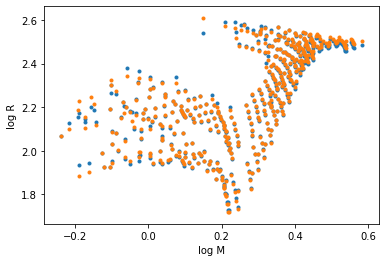

In [80]:
plot.scatter(logMData,logRData,marker='.')
plot.scatter(logMData, CalcLogR,marker='.')
plot.xlabel('log M')
plot.ylabel('log R')

Text(0, 0.5, 'log R (calculated)')

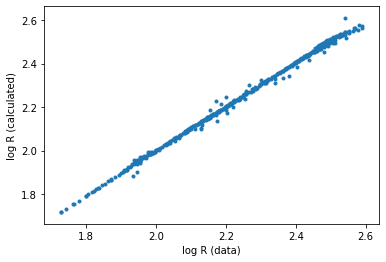

In [81]:
plot.scatter(logRData, CalcLogR,marker='.')
plot.xlabel('log R (data)')
plot.ylabel('log R (calculated)')

Text(0, 0.5, 'log R (data) - log R (calculated)')

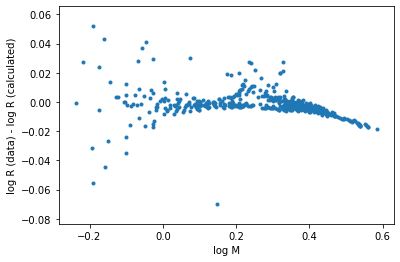

In [82]:
plot.scatter(logMData, logRData-CalcLogR,marker='.')
plot.xlabel('log M')
plot.ylabel('log R (data) - log R (calculated)')

In [83]:
inArray = np.transpose(np.vstack((FundlogRData,FundlogMData))) # Second, let's find logP0 = A + B logR + C logM
x = inArray
y = logP0Data
# x, y = np.array(x), np.array(y)
model = LinearRegression().fit(x, y)
# Returns a linear regression y = b0 + sum(b_i*x_i,i=1 to n)
r_sq = model.score(x, y)
print('coefficient of determination:', r_sq)
print('intercept:', model.intercept_) # b0
print('slope:', model.coef_) # b1, b2, b3,..., bn

coefficient of determination: 0.9825800573122307
intercept: -2.053992430966432
slope: [ 1.94312492 -0.82834175]


In [86]:
def P0Relation_for_M_stars (logRData,logMData):
    i = 0
    logP0Array = []
    while i < len(logMData):
        logR = logRData[i]
        logM = logMData[i]
        logP0 = -2.053992430966432 + 1.94312492*logR -0.82834175*logM
        logP0Array.append(logP0)
        i+=1
    return np.asarray(logP0Array)

CalcLogP0 = P0Relation_for_M_stars (FundlogRData,FundlogMData)

In [87]:
print('P0 Error:', mean_squared_error(logP0Data, CalcLogP0))

P0 Error: 0.0007128239264904945


Text(0, 0.5, 'log P0')

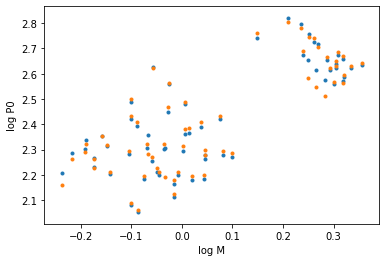

In [88]:
plot.scatter(FundlogMData,logP0Data, marker = ".")
plot.scatter(FundlogMData,CalcLogP0, marker = ".")
plot.xlabel('log M')
plot.ylabel('log P0')

Text(0, 0.5, 'log P0 (calculated)')

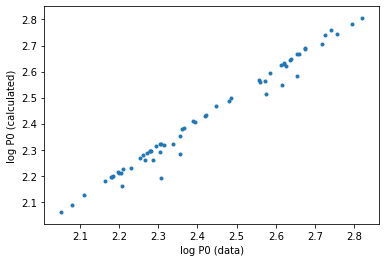

In [89]:
plot.scatter(logP0Data, CalcLogP0,marker='.')
plot.xlabel('log P0 (data)')
plot.ylabel('log P0 (calculated)')

Text(0, 0.5, 'log P0 (data) - log P0 (calculated)')

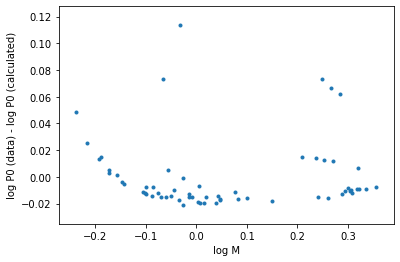

In [90]:
plot.scatter(FundlogMData, logP0Data-CalcLogP0,marker='.')
plot.xlabel('log M')
plot.ylabel('log P0 (data) - log P0 (calculated)')

In [91]:
inArray = np.transpose(np.vstack((FirstOverlogRData,FirstOverlogMData))) # Finally, let's find logP1 = A + B logR + C logM
x = inArray
y = logP1Data
# x, y = np.array(x), np.array(y)
model = LinearRegression().fit(x, y)
# Returns a linear regression y = b0 + sum(b_i*x_i,i=1 to n)
r_sq = model.score(x, y)
print('coefficient of determination:', r_sq)
print('intercept:', model.intercept_) # b0
print('slope:', model.coef_) # b1, b2, b3,..., bn

coefficient of determination: 0.9945222546844706
intercept: -1.6225583791213491
slope: [ 1.59820553 -0.51607087]


In [93]:
def P1Relation_for_M_stars (logRData,logMData):
    i = 0
    logP1Array = []
    while i < len(logMData):
        logR = logRData[i]
        logM = logMData[i]
        logP1 = -1.6225583791213491 + 1.59820553*logR -0.51607087*logM
        logP1Array.append(logP1)
        i+=1
    return np.asarray(logP1Array)

CalcLogP1 = P1Relation_for_M_stars (FirstOverlogRData,FirstOverlogMData)

In [94]:
print('P1 Error:', mean_squared_error(logP1Data, CalcLogP1))

P1 Error: 0.00041122633693616966


Text(0, 0.5, 'log P1')

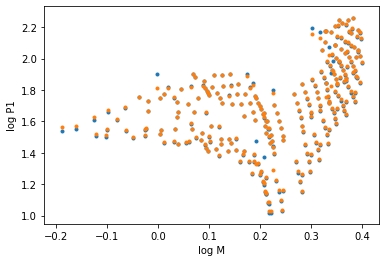

In [95]:
plot.scatter(FirstOverlogMData,logP1Data, marker=".")
plot.scatter(FirstOverlogMData,CalcLogP1, marker=".")
plot.xlabel('log M')
plot.ylabel('log P1')

Text(0, 0.5, 'log P1 (calculated)')

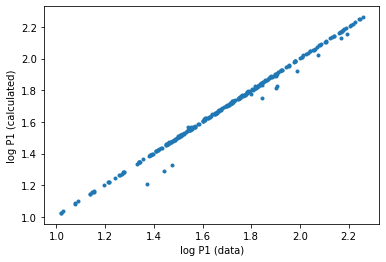

In [96]:
plot.scatter(logP1Data, CalcLogP1,marker='.')
plot.xlabel('log P1 (data)')
plot.ylabel('log P1 (calculated)')

Text(0, 0.5, 'log P1 (data) - log P1 (calculated)')

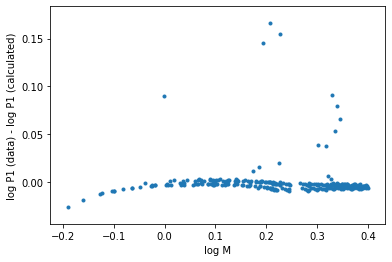

In [97]:
plot.scatter(FirstOverlogMData, logP1Data-CalcLogP1,marker='.')
plot.xlabel('log M')
plot.ylabel('log P1 (data) - log P1 (calculated)')